# 03b — Taxa manual da carteira

O mesmo fluxo do 03a (framework da SOA e monografia nº 5 da CAS), agora na carteira contra a BR-EMSmt 2026, com
**partição fora do tempo** como faz a SOA: treino com a experiência até 2023, teste em 2024.

$$
N_c \sim \text{Poisson}(\mu_c), \qquad \log \mu_c = \log E_c + \beta_0 + \beta_{cap}\,\log\frac{\text{capital}_c}{\text{ref}} + \beta_{\text{seção}(c)} + \dots
$$

| Candidato | Papel | Origem |
|---|---|---|
| Plano atual (tábua × A/E) | o que se compara | CAS 4.3.3 |
| GLM (capital e seção) | candidato a tarifa | SOA 4.1 |
| GLMM (+ efeito de divisão e de estipulante) | candidato a tarifa | adaptação: CAS 10.1 e evidência do 03a (grupos têm mortalidade própria) |
| Ridge com priori SOA | candidato a tarifa | adaptação: priori do estudo de mercado via penalização (SOA 4.3.1) |
| Elastic net (LASSO) + interações do LightGBM | referência de desempenho | SOA 4.3 |
| LightGBM | referência de desempenho | SOA 4.2 |

Elastic net com interações e LightGBM não viram tarifa: não cabem numa tabela de fatores explicável nem na nota
técnica. Se uma referência ganhar de todos os candidatos com significância, isso sinaliza estrutura faltando; a
interação mais forte apontada pelo LightGBM é testada diretamente no GLMM (seção 4).

**Regra de decisão** (fixada antes do teste, em `config/manual.yaml`): menor deviance no teste entre os candidatos a
tarifa; empates (IC de 95% da diferença, por bootstrap pareado **por estipulante**, contém zero) resolvidos pela
ordem de preferência. O escolhido é reajustado com toda a experiência maturada (CAS 4.3.3).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente abaixo
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, glmm as G, elasticnet as EN, diagnostico as D, avaliacao as A, prioris as PR
from vgpricing.graficos import estilo
estilo()

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cmo = (carregar_config(n, RAIZ) for n in ("base", "manual", "modelagem"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder and G.r_disponivel(), "Precisa da tábua oficial e do R (veja o README)"
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")               # gerado no 03a
FT = cm["fora_do_tempo"]
base = lambda janela: M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                                       cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"], janela=janela)
tr, itr = base((None, FT["treino_ate"]))
te, ite = base(tuple(FT["teste"]))
secoes_treino = set(tr["cnae_secao"])
te["cnae_secao"] = te["cnae_secao_original"].where(te["cnae_secao_original"].isin(secoes_treino), "OUTRAS")
pd.DataFrame({"período": [f"até {itr['corte_experiencia']}", f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}"],
              "óbitos": [itr["obitos"], ite["obitos"]], "esperados (tábua)": [itr["esperados"], ite["esperados"]],
              "estipulantes": [itr["estipulantes"], ite["estipulantes"]]}, index=["treino", "teste"])

,período,óbitos,esperados (tábua),estipulantes
treino,até 2023-12-31,1162,"1,135.5007",250
teste,2024-01-01 a 2024-12-31,524,497.5623,250


O teste usa o mapeamento de seções do treino (seções raras no treino viram "OUTRAS" nos dois).

## 1. GLM (SOA 4.1)

In [2]:
FIXOS = cm["modelo"]["fixos_obrigatorios"]
glm = M.ajustar_comparacao(tr, cm, FIXOS, "poisson")
an = G.ajustar_glmm(tr, FIXOS, [], categoricas=["cnae_secao"], numericas=["log_capital_c"],
                    niveis_base=M.niveis_base(tr, ["cnae_secao"]), anova=True).extra["anova"]
te["mu_glm"] = G.prever(glm, te)
print(f"Motor: {glm.extra['motor']} | dispersão de Pearson: {glm.extra['dispersao_pearson']:.3f}")
display(an)
glm.fixos.assign(fator=np.exp(glm.fixos["estimativa"]))

Motor: stats::glm | dispersão de Pearson: 1.999


,termo,gl,deviance,gl_residual,deviance_residual,p_valor
0,NULL,NaN,NaN,6308,"2,545.1023",NaN
1,log_capital_c,1.0000,13.0509,6307,"2,532.0514",0.0003
2,cnae_secao,9.0000,64.3271,6298,"2,467.7243",0.0000


,nome,estimativa,ep,fator
0,(Intercept),-0.2870,0.0764,0.7505
1,log_capital_c,-0.1143,0.0324,0.8920
2,cnae_secaoC,0.2469,0.1127,1.2800
3,cnae_secaoF,0.5654,0.1143,1.7601
4,cnae_secaoG,0.4845,0.1533,1.6234
5,cnae_secaoH,0.6581,0.1011,1.9312
6,cnae_secaoK,0.2582,0.1284,1.2946
7,cnae_secaoM,-0.0341,0.1746,0.9665
8,cnae_secaoN,0.2961,0.1045,1.3447
9,cnae_secaoP,0.0608,0.1449,1.0627


## 2. GLMM (adaptação: efeito de grupo)

O 03a mostrou, com dados reais, que grupos têm mortalidade própria além do que as variáveis explicam. Aqui o
estipulante é identificado, então entra como efeito aleatório; a divisão CNAE entra como efeito aleatório dentro da
seção (credibilidade de Ohlsson). Idade, sexo e porte são candidatos, testados por razão de verossimilhança com
correção de Holm.

In [3]:
glmm, _, testes = M.ajustar_taxa_manual(tr, cm)
te["mu_glmm"] = G.prever(glmm, te)
print("Fórmula:", glmm.formula)
print("Efeitos aleatórios retirados por variância nula (ajuste singular):", glmm.extra["aleatorios_removidos"] or "nenhum")
display(testes)
M.comparar_dispersao(tr, cm, glmm)

Fórmula: N ~ log_capital_c + cnae_secao + (1 | id_estipulante) + offset(log(E))
Efeitos aleatórios retirados por variância nula (ajuste singular): ['(1|cnae_secao:cnae_divisao)']


,termo,tipo,lr,gl,p_valor,p_holm,decisao
0,faixa_idade,fixo,0.4997,4,0.9735,0.9735,não entra
1,sexo,fixo,1.1012,1,0.2940,0.5880,não entra
2,faixa_tamanho,fixo,8.7313,3,0.0331,0.0993,não entra
3,(1|cnae_secao:cnae_divisao),aleatorio,0.0000,1,1.0000,NaN,estrutura (mantido)
4,(1|id_estipulante),aleatorio,6.7250,1,0.0048,NaN,estrutura (mantido)


,modelo,dispersão,loglik,parametros,AIC,dif_AIC_vs_melhor
0,GLM Poisson,nenhuma,"-2,060.5838",11,"4,143.1676",8.9048
1,Binomial Negativa (NB2),"por célula, independente","-2,059.8870",12,"4,143.7739",9.5112
2,GLMM (efeitos de divisão e estipulante),por grupo e por atividade,"-2,055.1314",12,"4,134.2627",0.0000


Com as log-verossimilhanças na mesma base (todas no mesmo pacote), o modelo com efeito de estipulante tem AIC menor
que a Binomial Negativa: a sobredispersão está no grupo, não na célula.

## 3. Ridge com priori SOA (adaptação)

A forma do estudo da SOA (elasticidade ao capital e fatores relativos de seção, 03a) entra no offset:

$$
\log \mu_c = \underbrace{\log E_c + \beta^{SOA}\log\tfrac{\text{capital}_c}{\text{ref}} + \log f^{SOA}_{\text{seção}(c)}}_{\text{offset}} + b_0 + \delta\,\log\tfrac{\text{capital}_c}{\text{ref}} + \gamma_{\text{seção}(c)} .
$$

A penalização ridge encolhe $\delta$ e $\gamma$ para zero, ou seja, para o estudo: é uma priori normal centrada na
SOA, e o lambda (validação cruzada por estipulante) faz o papel do k da credibilidade (SOA 4.3.1).

In [4]:
tr["fold"] = A.folds_por_grupo(tr["id_estipulante"], cm["validacao_cruzada"]["folds"], cm["validacao_cruzada"]["semente"]) + 1
for d in (tr, te):
    d["log_E"], d["off_priori"] = np.log(d["E"]), PR.offset_priori(d, prioris)
ridge = EN.ajustar_elastic_net(tr, {"teste": te}, ["log_capital_c", "cnae_secao"], ["cnae_secao"], ["log_capital_c"],
                               "off_priori", alpha=0.0, foldid="fold")
te["mu_ridge"] = ridge.previsoes["teste"]
pd.Series({"elasticidade SOA (priori)": prioris["elasticidade_capital"],
           "desvio estimado na carteira (δ)": ridge.coeficientes["log_capital_c"],
           "elasticidade final": prioris["elasticidade_capital"] + ridge.coeficientes["log_capital_c"],
           "elasticidade no GLM (sem priori)": glm.coef("log_capital_c"),
           "lambda (validação cruzada)": ridge.lambda_escolhido}).to_frame("valor")

,valor
elasticidade SOA (priori),-0.0986
desvio estimado na carteira (δ),-0.0039
elasticidade final,-0.1025
elasticidade no GLM (sem priori),-0.1143
lambda (validação cruzada),0.1852


## 4. Referências de desempenho: LightGBM e elastic net com interações (SOA 4.2 e 4.3)

In [5]:
VL = ["cnae_secao", "faixa_idade", "sexo", "log_capital_c", "faixa_tamanho"]
CL = [v for v in VL if v != "log_capital_c"]
lg = D.ajustar_residual(tr.assign(mu_manual=tr["E"]), D.config_lightgbm(cmo, "lightgbm_carteira", VL, CL))
te["mu_lgbm"] = D.prever(lg, te.assign(mu_manual=te["E"]))
inter = D.tabela_interacoes(lg["modelo"])
TOP = inter["interacao"].head(cmo["elastic_net"]["interacoes_do_lightgbm"]).tolist()
cen = cmo["elastic_net"]
en = EN.ajustar_elastic_net(tr, {"teste": te}, VL + TOP, CL, ["log_capital_c"], "log_E", alpha=cen["alpha"],
                            foldid="fold", lambda_=cen["lambda"], semente=cen["semente"], padronizar=cen["padronizar"])
te["mu_en"] = en.previsoes["teste"]
print(f"LightGBM: {lg['rodadas']} rodadas | interações para o elastic net: {TOP} | "
      f"coeficientes não nulos: {int((en.coeficientes.drop('(Intercept)') != 0).sum())}")
inter.head(5)

LightGBM: 189 rodadas | interações para o elastic net: ['cnae_secao:log_capital_c', 'cnae_secao:faixa_tamanho', 'faixa_tamanho:log_capital_c'] | coeficientes não nulos: 12


,interacao,sumGain,sumCover,frequency,meanCover,meanGain
0,cnae_secao:log_capital_c,472.8784,423790,142,"2,984.4366",3.3301
1,cnae_secao:faixa_tamanho,165.4322,122943,56,"2,195.4107",2.9541
2,faixa_tamanho:log_capital_c,137.9983,160600,50,"3,212.0000",2.7600
3,cnae_secao:faixa_idade,41.0638,49386,22,"2,244.8182",1.8665
4,faixa_idade:log_capital_c,30.5857,37502,16,"2,343.8750",1.9116


**Onde o LightGBM vê estrutura** (média do |SHAP| e SHAP por nível, como na SOA 4.2.4), e o **fechamento do ciclo**:
a interação mais forte da tabela vira uma hipótese concreta, testada no próprio GLMM por razão de verossimilhança.
Uma hipótese dirigida tem muito mais poder que a busca às cegas do LightGBM (o notebook 90 mede isso).

,média |SHAP|
cnae_secao,0.1355
log_capital_c,0.0729
faixa_tamanho,0.0469
faixa_idade,0.0072
sexo,0.0051


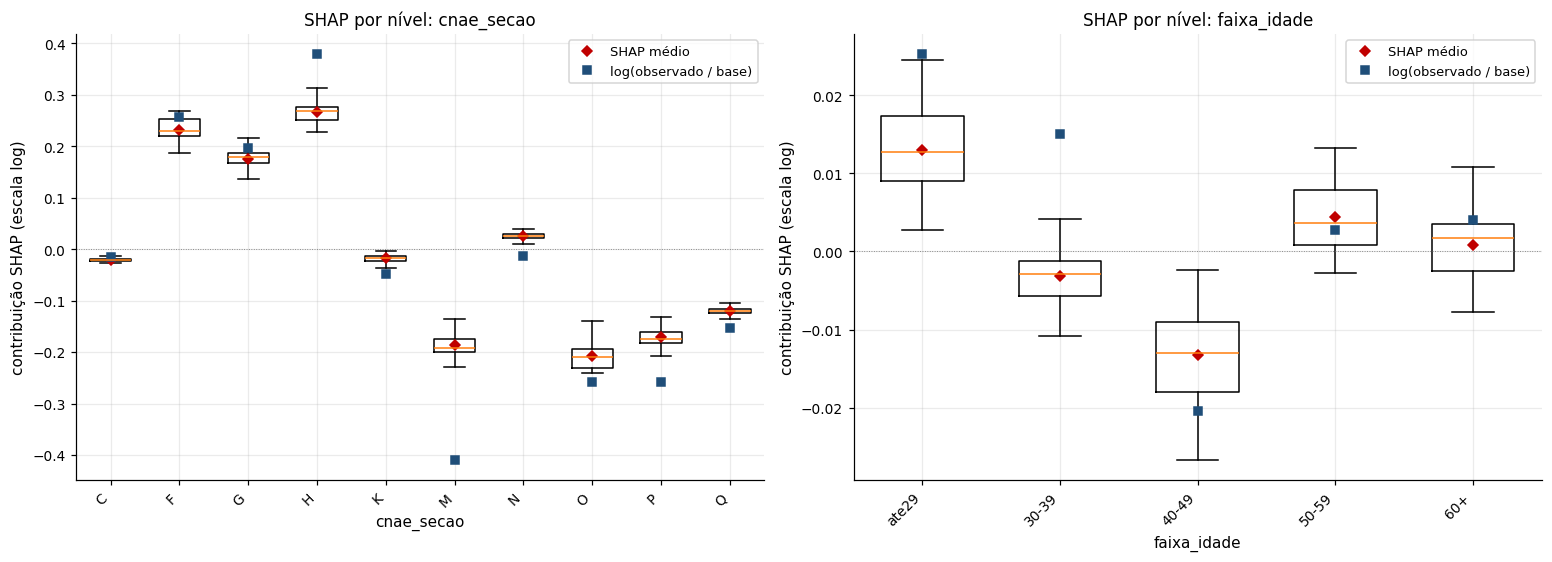

In [6]:
Xs = D._matriz(tr, VL, CL, lg["niveis"])
contrib = D.contribuicoes(lg["modelo"], Xs)
display(D.importancia(contrib, tr["E"].to_numpy()).to_frame("média |SHAP|"))
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, v, ordem in zip(axs, ["cnae_secao", "faixa_idade"], [None, cm["faixas"]["idade"]["rotulos"]]):
    D.grafico_shap(ax, contrib, tr.assign(mu_manual=tr["E"]), v, ordem=ordem)
plt.show()

In [7]:
a, b = TOP[0].split(":")
categ = [x for x in (a, b) if x in CL]
teste_dirigido = D.testar_candidato_glmm(tr, cm, FIXOS, [TOP[0]], categoricas_extras=[c for c in categ if c != "cnae_secao"])
print(f"Interação testada no GLMM: {TOP[0]}")
teste_dirigido[["termo", "lr", "gl", "p_valor"]]

Interação testada no GLMM: cnae_secao:log_capital_c


,termo,lr,gl,p_valor
0,cnae_secao:log_capital_c,9.7275,9,0.3730


Se o p-valor não for pequeno, a interação apontada pelo LightGBM não se sustenta como fator de tarifa nesta carteira,
e a taxa manual fica com os efeitos principais. Se for, ela entra como candidata, com a mesma regra de decisão.

## 5. Comparação no teste (2024)

In [8]:
te["mu_plano"] = te["E"] * tr["N"].sum() / tr["E"].sum()
PREV = {"plano atual (tábua × A/E)": "mu_plano", "GLM": "mu_glm", "GLMM": "mu_glmm", "ridge com priori SOA": "mu_ridge",
        "elastic net + interações": "mu_en", "LightGBM": "mu_lgbm"}
m = A.metricas(te, PREV)
m["Gini"] = [A.lorenz_gini(te, c)[1] for c in PREV.values()]
m["papel"] = ["tarifa" if n in cm["decisao"]["ordem_preferencia"] else "referência" for n in PREV]
m

,modelo,deviance,MSE,MAE,A/M total,deviance vs melhor,Gini,papel
0,plano atual (tábua × A/E),"1,784.5929",0.0881,0.1184,1.0291,7.8875,0.0352,tarifa
1,GLM,"1,782.3810",0.0884,0.1168,1.0322,5.6756,0.0775,tarifa
2,GLMM,"1,781.2152",0.0882,0.1169,1.0360,4.5098,0.0807,tarifa
3,ridge com priori SOA,"1,776.7054",0.0876,0.1166,1.0335,0.0000,0.0771,tarifa
4,elastic net + interações,"1,787.4288",0.0873,0.1175,1.0106,10.7234,0.0378,referência
5,LightGBM,"1,777.6895",0.0871,0.1174,1.0191,0.9841,0.0732,referência


In [9]:
TARIFA = {n: c for n, c in PREV.items() if n in cm["decisao"]["ordem_preferencia"]}
melhor = m[m["papel"] == "tarifa"].sort_values("deviance").iloc[0]["modelo"]
vs = A.comparar_modelos(te, PREV, melhor, unidade="id_estipulante", n_boot=cm["decisao"]["bootstrap"])
escolhido, empatados = M.escolher_modelo(vs[vs["modelo"].isin(TARIFA)], cm["decisao"]["ordem_preferencia"])
ref_melhor = vs[(~vs["modelo"].isin(TARIFA)) & vs["significativa"] & (vs[f"diferença vs {melhor}"] < 0)]
print(f"Menor deviance entre os candidatos a tarifa: {melhor}")
print(f"Empatados com ele: {empatados}  ->  escolhido pela ordem de preferência: {escolhido}")
print("Referência significativamente melhor que o melhor candidato:", ref_melhor["modelo"].tolist() or "nenhuma")
vs

Menor deviance entre os candidatos a tarifa: ridge com priori SOA
Empatados com ele: ['plano atual (tábua × A/E)', 'GLM', 'GLMM', 'ridge com priori SOA']  ->  escolhido pela ordem de preferência: ridge com priori SOA
Referência significativamente melhor que o melhor candidato: nenhuma


,modelo,deviance,diferença vs ridge com priori SOA,IC95 inf,IC95 sup,significativa
0,plano atual (tábua × A/E),272.6448,6.3505,-12.5407,25.8846,False
1,GLM,271.9679,5.6735,-2.0508,13.4389,False
2,GLMM,270.7938,4.4994,-1.9795,11.3217,False
3,ridge com priori SOA,266.2944,0.0000,0.0000,0.0000,False
4,elastic net + interações,275.6352,9.3408,-6.8290,27.9600,False
5,LightGBM,269.0343,2.7399,-5.1183,10.8078,False


Com cerca de 500 óbitos no ano de teste, as diferenças entre os candidatos não são significativas, e a escolha
recai sobre a ordem de preferência fixada antes. Nenhuma referência (LightGBM, elastic net com interações) ganha com
significância: não há sinal de estrutura faltando que justifique ir além de capital e seção.

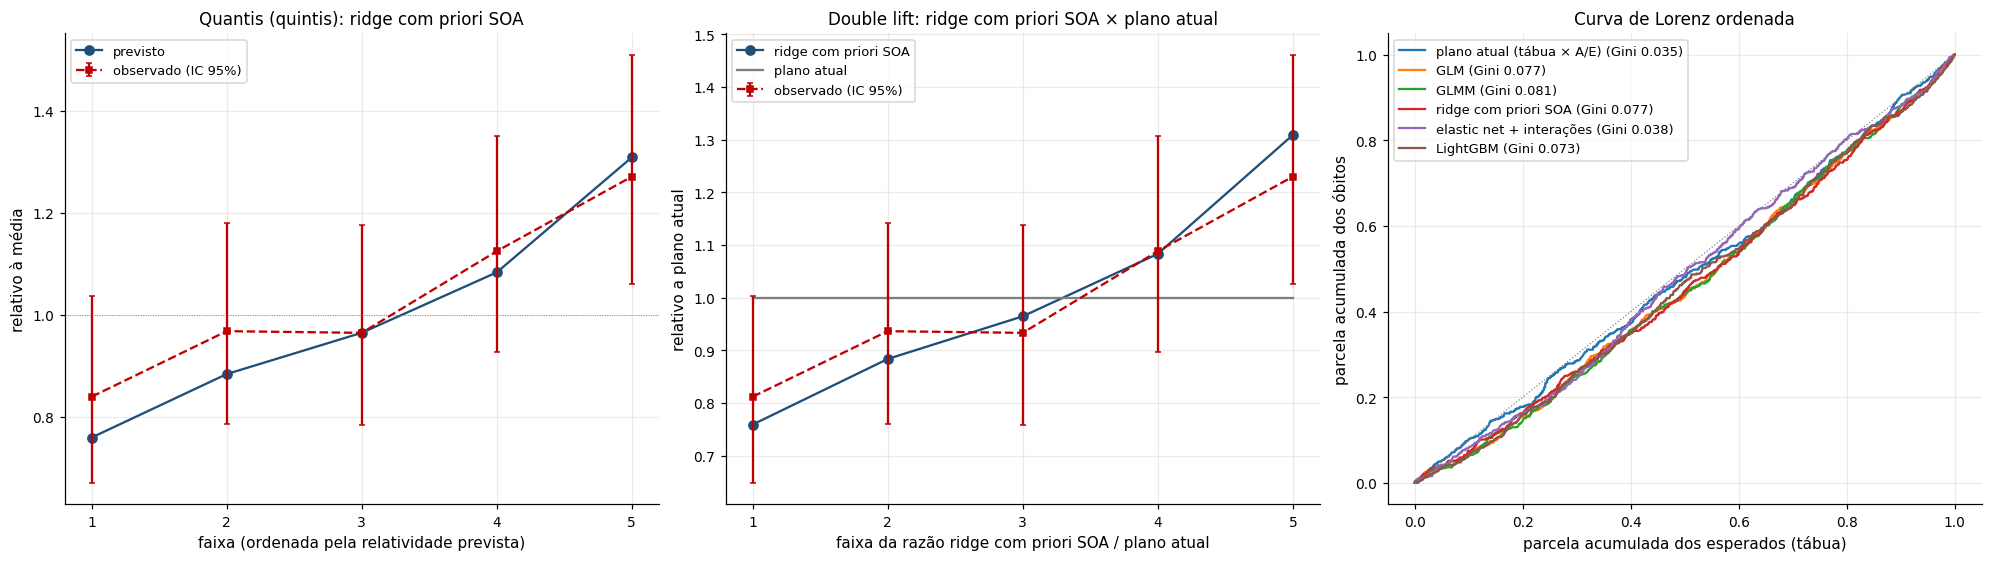

,variável,nível,N,mu_ridge,A/M,A/M inf,A/M sup,IC exclui 100%
0,faixa_capital,150-400k,60,51.8685,1.1568,0.8827,1.4890,False
1,faixa_capital,30-60k,173,160.5842,1.0773,0.9228,1.2504,False
2,faixa_capital,60-150k,124,138.2416,0.8970,0.7461,1.0695,False
3,faixa_capital,acima400k,10,7.4166,1.3483,0.6466,2.4796,False
4,faixa_capital,ate30k,157,148.8989,1.0544,0.8959,1.2328,False
0,cnae_secao,C,78,65.9914,1.1820,0.9343,1.4752,False
1,cnae_secao,F,49,59.9066,0.8179,0.6051,1.0814,False
2,cnae_secao,G,21,25.3334,0.8289,0.5131,1.2671,False
3,cnae_secao,H,84,84.5053,0.9940,0.7929,1.2307,False
4,cnae_secao,K,38,34.9089,1.0885,0.7703,1.4941,False


In [10]:
col = {'ridge com priori SOA': 'mu_ridge', 'GLMM': 'mu_glmm', 'GLM': 'mu_glm', 'plano atual (tábua × A/E)': 'mu_plano'}[escolhido]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
A.grafico_quantis(ax[0], A.quantis(te, col, n=5), f"Quantis (quintis): {escolhido}")
A.grafico_double_lift(ax[1], A.double_lift(te, col, "mu_plano", n=5), escolhido, "plano atual")
A.grafico_lorenz(ax[2], {n: A.lorenz_gini(te, c) for n, c in PREV.items()})
plt.show()
am = pd.concat([A.tabela_am(te, v, col).rename(columns={v: "nível"}).assign(variável=v) for v in ["faixa_capital", "cnae_secao"]])
am[["variável", "nível", "N", col, "A/M", "A/M inf", "A/M sup", "IC exclui 100%"]]

Quintis em vez de decis: com ~500 óbitos, decis teriam ~50 óbitos cada e intervalos largos demais.

## 6. Reajuste com toda a experiência e tabela de fatores

In [11]:
tudo, itudo = base(None)
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": itudo["corte_experiencia"],
        "obitos": itudo["obitos"], "esperados_tabua": round(itudo["esperados"], 2),
        "teste_fora_do_tempo": f"{ite['inicio_experiencia']} a {ite['corte_experiencia']}",
        "candidatos_empatados_no_teste": empatados, "secoes_agrupadas_em_OUTRAS": itudo["secoes_agrupadas_em_OUTRAS"]}
tabela = M.ajustar_tabela(tudo, escolhido, cm, prioris, meta)
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
print(f"Modelo: {escolhido} | A/E base: {tabela['ae_base']:.4f} | elasticidade ao capital: {tabela['capital']['elasticidade']:.4f}")
pd.Series(tabela["secao"]).sort_values().to_frame("fator de seção (base = 1)")

Modelo: ridge com priori SOA | A/E base: 0.8607 | elasticidade ao capital: -0.0980


,fator de seção (base = 1)
M,0.9545
P,0.9929
O,1.0000
Q,1.0295
J,1.0493
K,1.0855
S,1.1363
A,1.1803
N,1.2138
G,1.2195


## 7. Exemplo: taxa pura manual de um grupo

In [12]:
ref = pd.Timestamp(cfg["data_referencia"])
ativos = dados["vidas"][dados["vidas"]["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
grupo = porte.index[len(porte) // 2]
censo = ativos[ativos["id_estipulante"] == grupo]
e = dados["estipulantes"].set_index("id_estipulante").loc[grupo]
cot = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, ref + pd.Timedelta(days=1))
pd.Series({"estipulante": grupo, "atividade": f"{e['cnae_secao']}:{e['cnae_divisao']}", "vidas": cot["vidas"],
           "capital total (R$)": cot["capital_total"], "fator de atividade": cot["fator_atividade"],
           "prêmio puro anual (R$)": cot["premio_puro_anual"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "avisos": "; ".join(cot["avisos"]) or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0247
atividade,P:85
vidas,451
capital total (R$),"56,886,300.0000"
fator de atividade,0.9929
prêmio puro anual (R$),"91,468.6842"
taxa pura mensal (‰),0.1340
avisos,divisão sem experiência ['P:85']: usada a médi...


## Limitações
- **Um ano de teste com ~500 óbitos** não separa os candidatos: a escolha vem da ordem de preferência fixada antes.
  Na base real, com mais volume, o mesmo procedimento pode separar.
- **Carteira sintética:** os números refletem as hipóteses do gerador; a verificação de que o código recupera a
  verdade está no notebook 90.
- **Priori:** forma americana (2010–2013), mapeada para CNAE por julgamento; o lambda decide quanto a carteira se
  afasta dela.